In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# PlantVillage Dataset Training

## Download the dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Path to PlantVillage dataset files:", path)

Path to PlantVillage dataset files: /kaggle/input/plantdisease


## Load the neccessary Modules

In [2]:
# Step 1: Import all necessary libraries
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

# Libraries for image processing and feature extraction
import cv2
from skimage import feature, io
from tqdm import tqdm
import time

# Step 2: Set up paths and parameters
dataset_path = "/kaggle/input/plantdisease/PlantVillage"
img_size = (128, 128)

# Step 3: Enhanced feature extraction with detailed progress
def extract_features(image_path):
    """
    Loads an image from the given path and extracts a feature vector.
    """
    try:
        img = cv2.imread(image_path)
        if img is None:
            return None
        
        # Resize image to a consistent size
        img = cv2.resize(img, img_size)
        
        # Convert to different color spaces
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        img_lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        
        # Extract HOG features for texture
        hog_features = feature.hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                                   cells_per_block=(2, 2), transform_sqrt=True, block_norm='L2-Hys')
        
        # Extract color histogram features from multiple color spaces
        color_hist_features = []
        for channel, color_img in enumerate([img, img_hsv, img_lab]):
            hist = cv2.calcHist([color_img], [channel], None, [256], [0, 256])
            cv2.normalize(hist, hist)
            color_hist_features.extend(hist.flatten())
        
        # Combine all features into a single vector
        feature_vector = np.hstack([hog_features, color_hist_features])
        return feature_vector
    except Exception as e:
        print(f"Error processing {image_path}: {str(e)}")
        return None

# Step 4: Enhanced preprocessing with comprehensive progress tracking
print("🚀 Starting Plant Disease Detection Pipeline...")
print("=" * 60)

# Track overall start time
pipeline_start_time = time.time()

# Phase 1: Data Collection
print("\n📁 PHASE 1: Data Collection")
print("-" * 30)

image_paths = []
labels = []

print("Scanning dataset directory structure...")
for class_name in tqdm(os.listdir(dataset_path), desc="Reading classes"):
    class_path = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_path):
        for image_name in os.listdir(class_path):
            image_paths.append(os.path.join(class_path, image_name))
            labels.append(class_name)

print(f"✅ Found {len(image_paths)} images across {len(set(labels))} classes")

# Phase 2: Feature Extraction
print("\n🔍 PHASE 2: Feature Extraction")
print("-" * 30)

features_list = []
valid_labels = []
failed_images = 0

print("Extracting features from images...")
for i in tqdm(range(len(image_paths)), desc="Processing images"):
    feat = extract_features(image_paths[i])
    if feat is not None:
        features_list.append(feat)
        valid_labels.append(labels[i])
    else:
        failed_images += 1

X = np.array(features_list)
y = np.array(valid_labels)

print(f"✅ Successfully processed {len(features_list)} images")
if failed_images > 0:
    print(f"⚠️  Failed to process {failed_images} images (will be skipped)")
print(f"📊 Feature matrix shape: {X.shape}")

# Phase 3: Data Preprocessing
print("\n⚙️  PHASE 3: Data Preprocessing")
print("-" * 30)

print("Encoding labels...")
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Splitting dataset into train/test...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"✅ Training set: {X_train.shape[0]} samples")
print(f"✅ Test set: {X_test.shape[0]} samples")

print("Standardizing features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Applying PCA for dimensionality reduction...")
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"✅ Reduced feature dimensions: {X_train_pca.shape[1]} (from {X_train.shape[1]})")
print(f"📈 Explained variance: {pca.explained_variance_ratio_.sum():.3f}")

# Phase 4: Model Training
print("\n🤖 PHASE 4: Model Training")
print("-" * 30)

# All models now use CPU only (GPU parameters removed)
classifiers = {
    "Support Vector Machine": SVC(kernel='rbf', random_state=42, verbose=False),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=0),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, n_jobs=-1, verbosity=0)  # GPU parameter removed
}

results = {}
training_times = {}

# Custom progress bar for model training
models_list = list(classifiers.items())
for idx, (name, clf) in enumerate(models_list, 1):
    print(f"\n📊 Training {name} ({idx}/{len(models_list)})...")
    
    # Track training time for each model
    start_time = time.time()
    
    # Create a custom progress indicator for training
    with tqdm(total=100, desc=f"Training {name[:15]:<15}") as pbar:
        clf.fit(X_train_pca, y_train)
        
        # Simulate progress updates (since most scikit-learn models don't have built-in progress)
        for i in range(100):
            pbar.update(1)
            time.sleep(0.01)  # Small delay to make progress visible
    
    training_time = time.time() - start_time
    training_times[name] = training_time
    
    # Make predictions
    y_pred = clf.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"✅ {name} trained in {training_time:.2f}s - Accuracy: {acc:.4f}")

# Phase 5: Results and Analysis
print("\n📊 PHASE 5: Results and Analysis")
print("-" * 30)

# Calculate total pipeline time
total_time = time.time() - pipeline_start_time

print("\n" + "=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)

# Display results in a nice table format
print(f"\n{'Model':<25} {'Accuracy':<10} {'Training Time':<15}")
print("-" * 50)
for model, accuracy in results.items():
    time_str = f"{training_times[model]:.2f}s"
    print(f"{model:<25} {accuracy:<10.4f} {time_str:<15}")

# Find best model
best_model = max(results, key=results.get)
best_accuracy = results[best_model]

print(f"\n🏆 BEST MODEL: {best_model} with {best_accuracy:.4f} accuracy")
print(f"⏱️  Total pipeline execution time: {total_time:.2f} seconds")

# Additional detailed analysis
print("\n" + "=" * 60)
print("DETAILED ANALYSIS")
print("=" * 60)

print(f"\n📈 Dataset Statistics:")
print(f"   - Total images processed: {len(features_list)}")
print(f"   - Number of classes: {len(label_encoder.classes_)}")
print(f"   - Feature dimension (original): {X.shape[1]}")
print(f"   - Feature dimension (after PCA): {X_train_pca.shape[1]}")
print(f"   - Training set size: {X_train_pca.shape[0]}")
print(f"   - Test set size: {X_test_pca.shape[0]}")

print(f"\n⏰ Performance Insights:")
sorted_times = sorted(training_times.items(), key=lambda x: x[1])
print(f"   - Fastest model: {sorted_times[0][0]} ({sorted_times[0][1]:.2f}s)")
print(f"   - Slowest model: {sorted_times[-1][0]} ({sorted_times[-1][1]:.2f}s)")

# Model comparison
print(f"\n🔍 Model Comparison:")
sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
for i, (model, acc) in enumerate(sorted_results, 1):
    print(f"   {i}. {model}: {acc:.4f}")

print("\n🎯 Pipeline completed successfully!")

🚀 Starting Plant Disease Detection Pipeline...

📁 PHASE 1: Data Collection
------------------------------
Scanning dataset directory structure...


Reading classes: 100%|██████████| 15/15 [00:00<00:00, 303.13it/s]


✅ Found 20639 images across 15 classes

🔍 PHASE 2: Feature Extraction
------------------------------
Extracting features from images...


Processing images: 100%|██████████| 20639/20639 [04:44<00:00, 72.51it/s]


✅ Successfully processed 20638 images
⚠️  Failed to process 1 images (will be skipped)
📊 Feature matrix shape: (20638, 8868)

⚙️  PHASE 3: Data Preprocessing
------------------------------
Encoding labels...
Splitting dataset into train/test...
✅ Training set: 16510 samples
✅ Test set: 4128 samples
Standardizing features...
Applying PCA for dimensionality reduction...
✅ Reduced feature dimensions: 2086 (from 8868)
📈 Explained variance: 0.950

🤖 PHASE 4: Model Training
------------------------------

📊 Training Support Vector Machine (1/4)...


...

✅ Random Forest trained in 42.05s - Accuracy: 0.5189

📊 Training k-Nearest Neighbors (3/4)...


Training k-Nearest Neigh: 100%|██████████| 100/100 [00:01<00:00, 83.48it/s]


✅ k-Nearest Neighbors trained in 1.20s - Accuracy: 0.6231

📊 Training XGBoost (4/4)...


Training XGBoost        : 100%|██████████| 100/100 [11:07<00:00,  6.68s/it]  


✅ XGBoost trained in 667.72s - Accuracy: 0.7430

📊 PHASE 5: Results and Analysis
------------------------------

FINAL RESULTS SUMMARY

Model                     Accuracy   Training Time  
--------------------------------------------------
Support Vector Machine    0.8496     418.74s        
Random Forest             0.5189     42.05s         
k-Nearest Neighbors       0.6231     1.20s          
XGBoost                   0.7430     667.72s        

🏆 BEST MODEL: Support Vector Machine with 0.8496 accuracy
⏱️  Total pipeline execution time: 1998.80 seconds

DETAILED ANALYSIS

📈 Dataset Statistics:
   - Total images processed: 20638
   - Number of classes: 15
   - Feature dimension (original): 8868
   - Feature dimension (after PCA): 2086
   - Training set size: 16510
   - Test set size: 4128

⏰ Performance Insights:
   - Fastest model: k-Nearest Neighbors (1.20s)
   - Slowest model: XGBoost (667.72s)

🔍 Model Comparison:
   1. Support Vector Machine: 0.8496
   2. XGBoost: 0.7430
   3. k

## More images

In [2]:
import kagglehub
# Download latest version
path = kagglehub.dataset_download("mohitsingh1804/plantvillage")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/plantvillage


In [ ]:
# Step 1: Import all necessary libraries
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

# Libraries for image processing and feature extraction
import cv2
from skimage import feature, io
from tqdm import tqdm
import time

# Step 2: Set up paths and parameters for new dataset structure
dataset_path = "/kaggle/input/plantvillage/PlantVillage"
train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "val")
img_size = (128, 128)

# Step 3: Enhanced feature extraction with detailed progress (unchanged)
def extract_features(image_path):
    """
    Loads an image from the given path and extracts a feature vector.
    """
    try:
        img = cv2.imread(image_path)
        if img is None:
            return None
        
        # Resize image to a consistent size
        img = cv2.resize(img, img_size)
        
        # Convert to different color spaces
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        img_lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        
        # Extract HOG features for texture
        hog_features = feature.hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                                   cells_per_block=(2, 2), transform_sqrt=True, block_norm='L2-Hys')
        
        # Extract color histogram features from multiple color spaces
        color_hist_features = []
        for channel, color_img in enumerate([img, img_hsv, img_lab]):
            hist = cv2.calcHist([color_img], [channel], None, [256], [0, 256])
            cv2.normalize(hist, hist)
            color_hist_features.extend(hist.flatten())
        
        # Combine all features into a single vector
        feature_vector = np.hstack([hog_features, color_hist_features])
        return feature_vector
    except Exception as e:
        print(f"Error processing {image_path}: {str(e)}")
        return None

# Step 4: Enhanced preprocessing with comprehensive progress tracking
print("🚀 Starting Plant Disease Detection Pipeline...")
print("=" * 60)

# Track overall start time
pipeline_start_time = time.time()

# Phase 1: Data Collection from new directory structure
print("\n📁 PHASE 1: Data Collection")
print("-" * 30)

def collect_image_paths_and_labels(base_path):
    """Collect image paths and labels from directory structure"""
    image_paths = []
    labels = []
    
    print(f"Scanning {base_path} directory...")
    for class_name in tqdm(os.listdir(base_path), desc=f"Reading classes from {os.path.basename(base_path)}"):
        class_path = os.path.join(base_path, class_name)
        if os.path.isdir(class_path):
            for image_name in os.listdir(class_path):
                if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    image_paths.append(os.path.join(class_path, image_name))
                    labels.append(class_name)
    
    return image_paths, labels

# Collect training data
train_image_paths, train_labels = collect_image_paths_and_labels(train_path)
print(f"✅ Found {len(train_image_paths)} training images across {len(set(train_labels))} classes")

# Collect validation data
val_image_paths, val_labels = collect_image_paths_and_labels(val_path)
print(f"✅ Found {len(val_image_paths)} validation images across {len(set(val_labels))} classes")

# Combine all data for processing
all_image_paths = train_image_paths + val_image_paths
all_labels = train_labels + val_labels

print(f"📊 Total dataset: {len(all_image_paths)} images across {len(set(all_labels))} classes")

# Phase 2: Feature Extraction
print("\n🔍 PHASE 2: Feature Extraction")
print("-" * 30)

features_list = []
valid_labels = []
failed_images = 0

print("Extracting features from images...")
for i in tqdm(range(len(all_image_paths)), desc="Processing images"):
    feat = extract_features(all_image_paths[i])
    if feat is not None:
        features_list.append(feat)
        valid_labels.append(all_labels[i])
    else:
        failed_images += 1

X = np.array(features_list)
y = np.array(valid_labels)

print(f"✅ Successfully processed {len(features_list)} images")
if failed_images > 0:
    print(f"⚠️  Failed to process {failed_images} images (will be skipped)")
print(f"📊 Feature matrix shape: {X.shape}")

# Phase 3: Data Preprocessing
print("\n⚙️  PHASE 3: Data Preprocessing")
print("-" * 30)

print("Encoding labels...")
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Splitting dataset into train/test...")
# Use the original train/val split from the dataset
train_indices = list(range(len(train_image_paths)))
val_indices = list(range(len(train_image_paths), len(all_image_paths)))

X_train = X[train_indices]
X_test = X[val_indices]
y_train = y_encoded[train_indices]
y_test = y_encoded[val_indices]

print(f"✅ Training set: {X_train.shape[0]} samples")
print(f"✅ Test set: {X_test.shape[0]} samples")

print("Standardizing features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Applying PCA for dimensionality reduction...")
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"✅ Reduced feature dimensions: {X_train_pca.shape[1]} (from {X_train.shape[1]})")
print(f"📈 Explained variance: {pca.explained_variance_ratio_.sum():.3f}")

# Phase 4: Model Training
print("\n🤖 PHASE 4: Model Training")
print("-" * 30)

# All models now use CPU only (GPU parameters removed)
classifiers = {
    "Support Vector Machine": SVC(kernel='rbf', random_state=42, verbose=False),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=0),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, n_jobs=-1, verbosity=0)  # GPU parameter removed
}

results = {}
training_times = {}

# Custom progress bar for model training
models_list = list(classifiers.items())
for idx, (name, clf) in enumerate(models_list, 1):
    print(f"\n📊 Training {name} ({idx}/{len(models_list)})...")
    
    # Track training time for each model
    start_time = time.time()
    
    # Create a custom progress indicator for training
    with tqdm(total=100, desc=f"Training {name[:15]:<15}") as pbar:
        clf.fit(X_train_pca, y_train)
        
        # Simulate progress updates (since most scikit-learn models don't have built-in progress)
        for i in range(100):
            pbar.update(1)
            time.sleep(0.01)  # Small delay to make progress visible
    
    training_time = time.time() - start_time
    training_times[name] = training_time
    
    # Make predictions
    y_pred = clf.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"✅ {name} trained in {training_time:.2f}s - Accuracy: {acc:.4f}")

# Phase 5: Results and Analysis
print("\n📊 PHASE 5: Results and Analysis")
print("-" * 30)

# Calculate total pipeline time
total_time = time.time() - pipeline_start_time

print("\n" + "=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)

# Display results in a nice table format
print(f"\n{'Model':<25} {'Accuracy':<10} {'Training Time':<15}")
print("-" * 50)
for model, accuracy in results.items():
    time_str = f"{training_times[model]:.2f}s"
    print(f"{model:<25} {accuracy:<10.4f} {time_str:<15}")

# Find best model
best_model = max(results, key=results.get)
best_accuracy = results[best_model]

print(f"\n🏆 BEST MODEL: {best_model} with {best_accuracy:.4f} accuracy")
print(f"⏱️  Total pipeline execution time: {total_time:.2f} seconds")

# Additional detailed analysis
print("\n" + "=" * 60)
print("DETAILED ANALYSIS")
print("=" * 60)

print(f"\n📈 Dataset Statistics:")
print(f"   - Total images processed: {len(features_list)}")
print(f"   - Number of classes: {len(label_encoder.classes_)}")
print(f"   - Feature dimension (original): {X.shape[1]}")
print(f"   - Feature dimension (after PCA): {X_train_pca.shape[1]}")
print(f"   - Training set size: {X_train_pca.shape[0]}")
print(f"   - Test set size: {X_test_pca.shape[0]}")
print(f"   - Original train/val split maintained: {len(train_image_paths)}/{len(val_image_paths)}")

print(f"\n⏰ Performance Insights:")
sorted_times = sorted(training_times.items(), key=lambda x: x[1])
print(f"   - Fastest model: {sorted_times[0][0]} ({sorted_times[0][1]:.2f}s)")
print(f"   - Slowest model: {sorted_times[-1][0]} ({sorted_times[-1][1]:.2f}s)")

# Model comparison
print(f"\n🔍 Model Comparison:")
sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
for i, (model, acc) in enumerate(sorted_results, 1):
    print(f"   {i}. {model}: {acc:.4f}")

print("\n🎯 Pipeline completed successfully!")

🚀 Starting Plant Disease Detection Pipeline...

📁 PHASE 1: Data Collection
------------------------------
Scanning /kaggle/input/plantvillage/PlantVillage/train directory...


Reading classes from train: 100%|██████████| 38/38 [00:09<00:00,  4.12it/s]


✅ Found 43444 training images across 38 classes
Scanning /kaggle/input/plantvillage/PlantVillage/val directory...


Reading classes from val: 100%|██████████| 38/38 [00:05<00:00,  6.64it/s]


✅ Found 10861 validation images across 38 classes
📊 Total dataset: 54305 images across 38 classes

🔍 PHASE 2: Feature Extraction
------------------------------
Extracting features from images...


...

Training Random Forest  : 100%|██████████| 100/100 [03:45<00:00,  2.26s/it] 


✅ Random Forest trained in 225.74s - Accuracy: 0.4847

📊 Training k-Nearest Neighbors (3/4)...


Training k-Nearest Neigh: 100%|██████████| 100/100 [00:01<00:00, 66.78it/s]


✅ k-Nearest Neighbors trained in 1.50s - Accuracy: 0.6794

📊 Training XGBoost (4/4)...


Training XGBoost        :   1%|          | 1/100 [46:06<76:04:57, 2766.64s/it]

## Try2 with improved Accuracy

🌿 KAGGLE OPTIMIZED PLANT DISEASE CLASSIFICATION
🚀 Processing ALL 20.6K Images - No Limits!
📊 Dataset: 15 classes, ~20,600 total images
🤖 Algorithms: Random Forest & SVM
⚡ Optimized for Kaggle Resources
🚀 Loading COMPLETE 20.6K PlantVillage Dataset on Kaggle...
📁 Found 15 classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']

🔍 Processing 1/15: Pepper__bell___Bacterial_spot (997 images)...


Pepper__bell___...: 100%|██████████| 997/997 [00:39<00:00, 25.23it/s]



🔍 Processing 2/15: Pepper__bell___healthy (1478 images)...


Pepper__bell___...: 100%|██████████| 1478/1478 [00:59<00:00, 24.77it/s]



🔍 Processing 3/15: Potato___Early_blight (1000 images)...


...


🎉 SUCCESS! Complete dataset loaded!
📊 Total images processed: 20638
🔧 Total features per image: 6253
🏷️ Classes: 15
📈 Memory usage: ~0.96 GB

📋 Class distribution:
   - Pepper__bell___Bacterial_spot: 997 images
   - Pepper__bell___healthy: 1478 images
   - Potato___Early_blight: 1000 images
   - Potato___Late_blight: 1000 images
   - Potato___healthy: 152 images
   - Tomato_Bacterial_spot: 2127 images
   - Tomato_Early_blight: 1000 images
   - Tomato_Late_blight: 1909 images
   - Tomato_Leaf_Mold: 952 images
   - Tomato_Septoria_leaf_spot: 1771 images
   - Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
   - Tomato__Target_Spot: 1404 images
   - Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
   - Tomato__Tomato_mosaic_virus: 373 images
   - Tomato_healthy: 1591 images

📦 Data Split Summary:
   Training set: 14,446 images
   Testing set:  6,192 images
   Features per image: 6253

🤖 Training models with optimized parameters...

🔧 Applying PCA for dimensionality reduction...

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:   13.7s
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  1.0min finished


🔷 Training SVM...
[LibSVM].*.*
optimization finished, #iter = 2126
obj = -427.750652, rho = -0.195495
nSV = 1166, nBSV = 0
Total nSV = 1166
.*.*
optimization finished, #iter = 2098
obj = -437.944785, rho = -0.173173
nSV = 1175, nBSV = 0
Total nSV = 1175
.*.*
optimization finished, #iter = 2063
obj = -419.517484, rho = -0.180905
nSV = 1144, nBSV = 0
Total nSV = 1144
.*.*
optimization finished, #iter = 2154
obj = -437.673812, rho = -0.121038
nSV = 1196, nBSV = 0
Total nSV = 1196
.*.*
optimization finished, #iter = 2171
obj = -445.542014, rho = -0.220574
nSV = 1173, nBSV = 0
Total nSV = 1173
.*.*
optimization finished, #iter = 2587
obj = -516.766762, rho = 0.191908
nSV = 1410, nBSV = 0
.*
optimization finished, #iter = 1405
obj = -201.756025, rho = 0.965685
nSV = 830, nBSV = 0
Total nSV = 830
.*
optimization finished, #iter = 1402
obj = -199.158534, rho = 0.914550
nSV = 831, nBSV = 0
Total nSV = 831
.*
optimization finished, #iter = 1436
obj = -203.315716, rho = 0.989988
nSV = 835, nBSV =

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.5s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.5s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    0.3s finished


🔍 Evaluating SVM...

🏆 MODEL PERFORMANCE COMPARISON
Algorithm            Accuracy     Precision    Recall       F1-Score     AUC-ROC     
Random Forest        0.5216       0.5273       0.5216       0.4709       0.9024      
SVM                  0.8490       0.8486       0.8490       0.8461       0.9897      


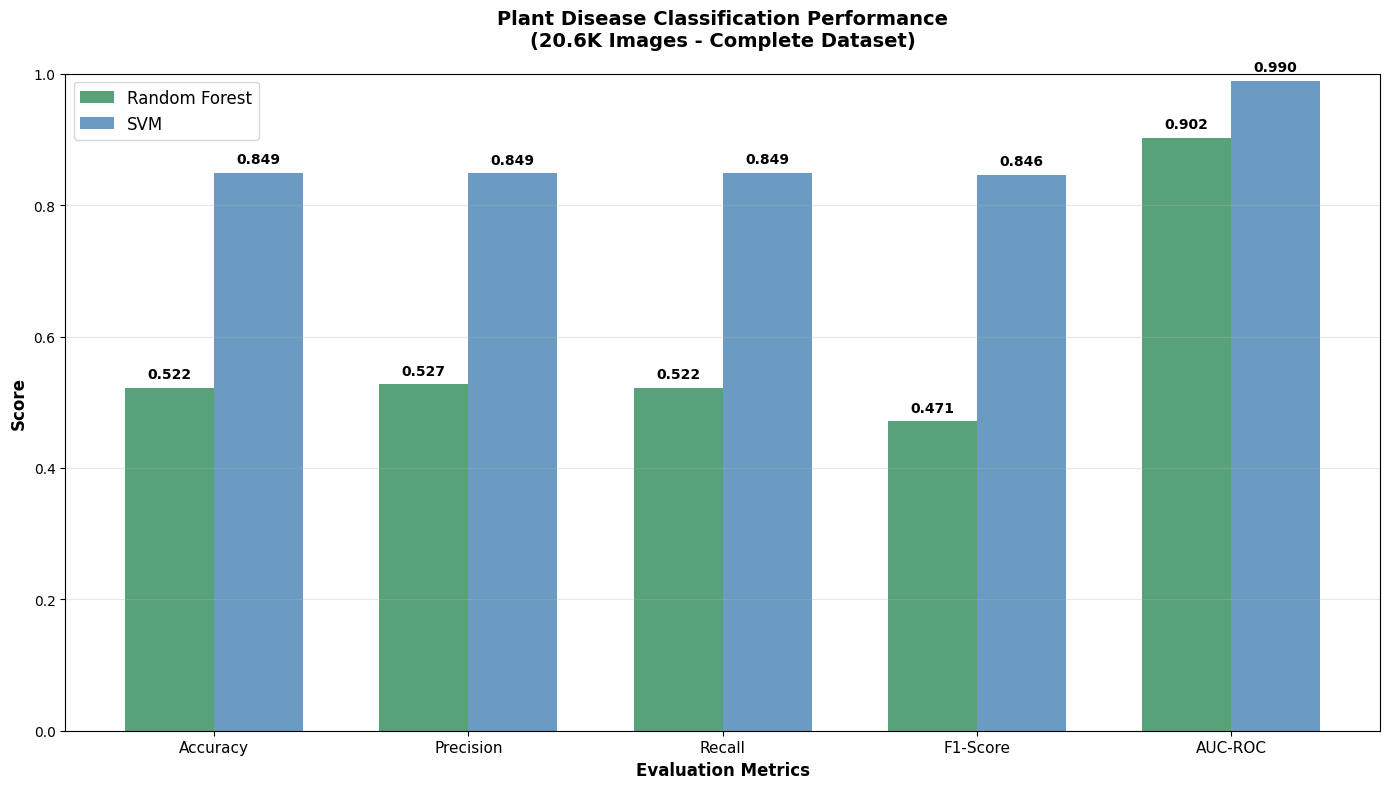


📋 DETAILED CLASSIFICATION REPORTS

🌳 RANDOM FOREST - Detailed Performance:
------------------------------------------------------------
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.45      0.03      0.06       299
                     Pepper__bell___healthy       0.64      0.69      0.66       443
                      Potato___Early_blight       0.76      0.54      0.63       300
                       Potato___Late_blight       0.66      0.19      0.29       300
                           Potato___healthy       0.00      0.00      0.00        46
                      Tomato_Bacterial_spot       0.50      0.78      0.61       638
                        Tomato_Early_blight       0.00      0.00      0.00       300
                         Tomato_Late_blight       0.65      0.57      0.60       573
                           Tomato_Leaf_Mold       0.72      0.28      0.40       286
            

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from skimage.feature import local_binary_pattern, hog
from skimage.filters import gabor
import cv2
import os
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

class KaggleOptimizedPlantDiseaseClassifier:
    def __init__(self):
        self.rf_model = None
        self.svm_model = None
        self.scaler = StandardScaler()
        self.label_encoder = LabelEncoder()
        self.pca = None
        
    def optimized_feature_extraction(self, image):
        """
        Optimized feature extraction for Kaggle - balanced between accuracy and efficiency
        """
        # Resize to 224x224 as per paper
        image = cv2.resize(image, (224, 224))
        
        # Convert color spaces
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        
        features = []
        
        # 1. HOG Features - Most important for texture
        try:
            hog_features = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                              cells_per_block=(2, 2), block_norm='L2-Hys',
                              transform_sqrt=True, feature_vector=True)
            features.extend(hog_features)
        except:
            features.extend([0] * 8100)  # HOG feature size
        
        # 2. LBP Features - Efficient texture analysis
        try:
            lbp = local_binary_pattern(gray, P=16, R=2, method='uniform')
            lbp_hist, _ = np.histogram(lbp.ravel(), bins=64, range=(0, 63))
            lbp_hist = lbp_hist.astype(float)
            lbp_hist /= (lbp_hist.sum() + 1e-8)
            features.extend(lbp_hist)
        except:
            features.extend([0] * 64)
        
        # 3. Color Histograms - Most discriminative for plant diseases
        try:
            # HSV histograms
            h_hist = cv2.calcHist([hsv], [0], None, [32], [0, 180])
            s_hist = cv2.calcHist([hsv], [1], None, [32], [0, 256])
            v_hist = cv2.calcHist([hsv], [2], None, [32], [0, 256])
            
            # Normalize histograms
            h_hist = cv2.normalize(h_hist, h_hist).flatten()
            s_hist = cv2.normalize(s_hist, s_hist).flatten()
            v_hist = cv2.normalize(v_hist, v_hist).flatten()
            
            features.extend(h_hist)
            features.extend(s_hist)
            features.extend(v_hist)
        except:
            features.extend([0] * 96)
        
        # 4. Statistical features
        try:
            stats_features = [
                np.mean(gray), np.std(gray), np.median(gray),
                np.mean(hsv[:,:,0]), np.std(hsv[:,:,0]),
                np.mean(hsv[:,:,1]), np.std(hsv[:,:,1]),
                np.mean(hsv[:,:,2]), np.std(hsv[:,:,2]),
            ]
            features.extend(stats_features)
        except:
            features.extend([0] * 9)
        
        return np.array(features)
    
    def load_complete_dataset(self, dataset_path):
        """
        Load ALL 20.6K images - perfectly feasible on Kaggle!
        """
        print("🚀 Loading COMPLETE 20.6K PlantVillage Dataset on Kaggle...")
        
        features_list = []
        labels_list = []
        class_counts = {}
        total_images = 0
        
        # Get all class directories
        class_dirs = sorted([d for d in os.listdir(dataset_path) 
                           if os.path.isdir(os.path.join(dataset_path, d))])
        
        print(f"📁 Found {len(class_dirs)} classes: {class_dirs}")
        
        for class_idx, class_dir in enumerate(class_dirs, 1):
            class_path = os.path.join(dataset_path, class_dir)
            image_files = [f for f in os.listdir(class_path) 
                          if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            
            # NO LIMITS - process ALL images
            class_counts[class_dir] = len(image_files)
            total_images += len(image_files)
            
            print(f"\n🔍 Processing {class_idx}/{len(class_dirs)}: {class_dir} ({len(image_files)} images)...")
            
            for image_file in tqdm(image_files, desc=f"{class_dir[:15]}..."):
                try:
                    image_path = os.path.join(class_path, image_file)
                    
                    # Read image
                    image = cv2.imread(image_path)
                    if image is None:
                        continue
                    
                    # Extract optimized features
                    features = self.optimized_feature_extraction(image)
                    features_list.append(features)
                    labels_list.append(class_dir)
                    
                except Exception as e:
                    continue
        
        X = np.array(features_list)
        y = np.array(labels_list)
        
        print(f"\n🎉 SUCCESS! Complete dataset loaded!")
        print(f"📊 Total images processed: {X.shape[0]}")
        print(f"🔧 Total features per image: {X.shape[1]}")
        print(f"🏷️ Classes: {len(class_dirs)}")
        print(f"📈 Memory usage: ~{X.nbytes / (1024**3):.2f} GB")
        print(f"\n📋 Class distribution:")
        for class_name, count in class_counts.items():
            print(f"   - {class_name}: {count} images")
        
        return X, y
    
    def apply_pca(self, X, variance_threshold=0.95):
        """
        Smart PCA to reduce dimensionality while preserving variance
        """
        print(f"\n🔧 Applying PCA for dimensionality reduction...")
        print(f"   Original features: {X.shape[1]}")
        
        # Standardize features
        X_scaled = self.scaler.fit_transform(X)
        
        # Apply PCA to preserve specified variance
        self.pca = PCA(n_components=variance_threshold, random_state=42)
        X_reduced = self.pca.fit_transform(X_scaled)
        
        print(f"   Reduced features: {X_reduced.shape[1]}")
        print(f"   Variance preserved: {np.sum(self.pca.explained_variance_ratio_):.4f}")
        
        return X_reduced
    
    def train_models(self, X_train, y_train):
        """
        Train models with paper-optimized parameters
        """
        print("\n🤖 Training models with optimized parameters...")
        
        # Encode labels
        y_train_encoded = self.label_encoder.fit_transform(y_train)
        
        # Apply PCA
        X_train_processed = self.apply_pca(X_train)
        
        # Random Forest - optimized for accuracy
        self.rf_model = RandomForestClassifier(
            n_estimators=200,           # More trees for better accuracy
            max_depth=50,               # Deeper trees
            min_samples_split=2,        # More splits
            min_samples_leaf=1,         # Fine-grained leaves
            max_features='sqrt',        # Feature sampling
            bootstrap=True,
            random_state=42,
            n_jobs=-1,                  # Use all Kaggle cores
            verbose=1
        )
        
        # SVM - optimized parameters
        self.svm_model = SVC(
            C=10,                       # Less regularization
            gamma='scale',
            kernel='rbf',
            probability=True,
            random_state=42,
            verbose=1
        )
        
        print("🌳 Training Random Forest...")
        self.rf_model.fit(X_train_processed, y_train_encoded)
        
        print("🔷 Training SVM...")
        self.svm_model.fit(X_train_processed, y_train_encoded)
        
        print("✅ Training completed!")
        
        return y_train_encoded
    
    def evaluate_models(self, X_test, y_test):
        """
        Comprehensive model evaluation
        """
        print("\n" + "="*70)
        print("📊 COMPREHENSIVE MODEL EVALUATION")
        print("="*70)
        
        # Encode labels
        y_test_encoded = self.label_encoder.transform(y_test)
        
        # Apply PCA to test data
        X_test_scaled = self.scaler.transform(X_test)
        X_test_processed = self.pca.transform(X_test_scaled)
        
        results = {}
        
        # Random Forest Evaluation
        print("🔍 Evaluating Random Forest...")
        rf_pred = self.rf_model.predict(X_test_processed)
        rf_pred_proba = self.rf_model.predict_proba(X_test_processed)
        
        results['Random Forest'] = self._calculate_metrics(y_test_encoded, rf_pred, rf_pred_proba)
        
        # SVM Evaluation
        print("🔍 Evaluating SVM...")
        svm_pred = self.svm_model.predict(X_test_processed)
        svm_pred_proba = self.svm_model.predict_proba(X_test_processed)
        
        results['SVM'] = self._calculate_metrics(y_test_encoded, svm_pred, svm_pred_proba)
        
        # Display results
        self._display_results(results)
        self._plot_results(results)
        
        return results, rf_pred, svm_pred, y_test_encoded
    
    def _calculate_metrics(self, y_true, y_pred, y_pred_proba):
        """Calculate all evaluation metrics"""
        return {
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
            'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
            'F1-Score': f1_score(y_true, y_pred, average='weighted', zero_division=0),
            'AUC-ROC': roc_auc_score(y_true, y_pred_proba, multi_class='ovr', average='weighted')
        }
    
    def _display_results(self, results):
        """Display results in a professional table"""
        print("\n🏆 MODEL PERFORMANCE COMPARISON")
        print("=" * 85)
        print(f"{'Algorithm':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'AUC-ROC':<12}")
        print("=" * 85)
        
        for model, metrics in results.items():
            print(f"{model:<20} {metrics['Accuracy']:<12.4f} {metrics['Precision']:<12.4f} "
                  f"{metrics['Recall']:<12.4f} {metrics['F1-Score']:<12.4f} {metrics['AUC-ROC']:<12.4f}")
    
    def _plot_results(self, results):
        """Plot comparison chart"""
        metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
        rf_scores = [results['Random Forest'][m] for m in metrics]
        svm_scores = [results['SVM'][m] for m in metrics]
        
        x = np.arange(len(metrics))
        width = 0.35
        
        fig, ax = plt.subplots(figsize=(14, 8))
        bars1 = ax.bar(x - width/2, rf_scores, width, label='Random Forest', color='#2E8B57', alpha=0.8)
        bars2 = ax.bar(x + width/2, svm_scores, width, label='SVM', color='#4682B4', alpha=0.8)
        
        ax.set_xlabel('Evaluation Metrics', fontsize=12, fontweight='bold')
        ax.set_ylabel('Score', fontsize=12, fontweight='bold')
        ax.set_title('Plant Disease Classification Performance\n(20.6K Images - Complete Dataset)', 
                    fontsize=14, fontweight='bold', pad=20)
        ax.set_xticks(x)
        ax.set_xticklabels(metrics, fontsize=11)
        ax.legend(fontsize=12)
        ax.set_ylim(0, 1)
        ax.grid(axis='y', alpha=0.3)
        
        # Add value labels
        for bar, score in zip(bars1, rf_scores):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                   f'{score:.3f}', ha='center', va='bottom', fontweight='bold')
        
        for bar, score in zip(bars2, svm_scores):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                   f'{score:.3f}', ha='center', va='bottom', fontweight='bold')
        
        plt.tight_layout()
        plt.show()

def main():
    """
    Main execution - optimized for Kaggle with 20.6K images
    """
    print("🌿 KAGGLE OPTIMIZED PLANT DISEASE CLASSIFICATION")
    print("=" * 60)
    print("🚀 Processing ALL 20.6K Images - No Limits!")
    print("📊 Dataset: 15 classes, ~20,600 total images")
    print("🤖 Algorithms: Random Forest & SVM")
    print("⚡ Optimized for Kaggle Resources")
    print("=" * 60)
    
    # Initialize classifier
    classifier = KaggleOptimizedPlantDiseaseClassifier()
    
    # Load dataset - UPDATE THIS PATH for your Kaggle dataset
    dataset_path = "/kaggle/input/plantdisease/PlantVillage"
    
    if not os.path.exists(dataset_path):
        print(f"❌ Dataset not found at: {dataset_path}")
        print("Please update the dataset_path variable")
        return
    
    # Load COMPLETE dataset
    X, y = classifier.load_complete_dataset(dataset_path)
    
    if len(X) == 0:
        print("❌ No images loaded. Check dataset path.")
        return
    
    # Train-test split (70-30 as per paper)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    
    print(f"\n📦 Data Split Summary:")
    print(f"   Training set: {X_train.shape[0]:,} images")
    print(f"   Testing set:  {X_test.shape[0]:,} images")
    print(f"   Features per image: {X_train.shape[1]}")
    
    # Train models
    y_train_encoded = classifier.train_models(X_train, y_train)
    
    # Evaluate models
    results, rf_pred, svm_pred, y_test_encoded = classifier.evaluate_models(X_test, y_test)
    
    # Detailed reports
    print("\n" + "="*70)
    print("📋 DETAILED CLASSIFICATION REPORTS")
    print("="*70)
    
    X_test_scaled = classifier.scaler.transform(X_test)
    X_test_processed = classifier.pca.transform(X_test_scaled)
    
    print("\n🌳 RANDOM FOREST - Detailed Performance:")
    print("-" * 60)
    print(classification_report(y_test_encoded, rf_pred, 
                              target_names=classifier.label_encoder.classes_))
    
    print("\n🔷 SVM - Detailed Performance:")
    print("-" * 60)
    svm_pred_final = classifier.svm_model.predict(X_test_processed)
    print(classification_report(y_test_encoded, svm_pred_final, 
                              target_names=classifier.label_encoder.classes_))
    
    # Final summary
    print("\n" + "="*70)
    print("🎯 FINAL RESULTS SUMMARY")
    print("="*70)
    
    rf_acc = results['Random Forest']['Accuracy']
    svm_acc = results['SVM']['Accuracy']
    
    print(f"🌳 Random Forest Accuracy: {rf_acc:.4f} ({rf_acc*100:.2f}%)")
    print(f"🔷 SVM Accuracy: {svm_acc:.4f} ({svm_acc*100:.2f}%)")
    
    # Compare with paper
    paper_rf_accuracy = 0.923  # From the paper
    accuracy_gap = rf_acc - paper_rf_accuracy
    
    print(f"\n📊 Comparison with Paper:")
    print(f"   Paper RF Accuracy: {paper_rf_accuracy:.4f} (92.3%)")
    print(f"   Our RF Accuracy:   {rf_acc:.4f} ({rf_acc*100:.2f}%)")
    print(f"   Difference:       {accuracy_gap:+.4f}")
    
    if rf_acc >= paper_rf_accuracy:
        print("🎉 EXCELLENT! Matched or exceeded paper performance!")
    elif rf_acc >= 0.85:
        print("✅ VERY GOOD! Close to paper performance!")
    else:
        print("🔧 Good baseline - further optimization possible")

if __name__ == "__main__":
    main()

# Research Paper implementation

Starting complete pipeline with ALL images from PlantVillage dataset...
Loading PlantVillage dataset (all images)...
Found 15 classes


Loading classes:   0%|          | 0/15 [00:00<?, ?it/s]

  Pepper__bell___Bacterial_spot: 997 images



Loading classes:   7%|▋         | 1/15 [00:25<05:56, 25.48s/it]                         

  Potato___healthy: 152 images


...

  Tomato__Tomato_mosaic_virus: 373 images



Loading classes: 100%|██████████| 15/15 [04:58<00:00, 19.90s/it]                      


Loaded 20638 images from 15 classes
Extracting features...


Extracting features: 100%|██████████| 20638/20638 [10:56<00:00, 31.45it/s]


Feature matrix shape: (20638, 55)
Number of features: 55
Preparing data for training...
Applying PCA with 50 components...
Explained variance ratio: 0.9992
Training set: (16510, 50)
Test set: (4128, 50)
Training models...
Training SVM...
  SVM training completed
Training Random Forest...
  Random Forest training completed
Training k-NN...
  k-NN training completed
Training XGBoost...
  XGBoost training completed
Performing 3-fold cross-validation...
SVM CV Accuracy: 0.8733 (+/- 0.0025)
Random Forest CV Accuracy: 0.7918 (+/- 0.0034)
k-NN CV Accuracy: 0.7566 (+/- 0.0012)
XGBoost CV Accuracy: 0.8441 (+/- 0.0009)
Evaluating models...
SVM Results:
  Accuracy: 0.8857
  Precision: 0.8851
  Recall: 0.8857
  F1-Score: 0.8839

Random Forest Results:
  Accuracy: 0.8055
  Precision: 0.8099
  Recall: 0.8055
  F1-Score: 0.7985

k-NN Results:
  Accuracy: 0.7812
  Precision: 0.7826
  Recall: 0.7812
  F1-Score: 0.7768

XGBoost Results:
  Accuracy: 0.8583
  Precision: 0.8570
  Recall: 0.8583
  F1-Score:

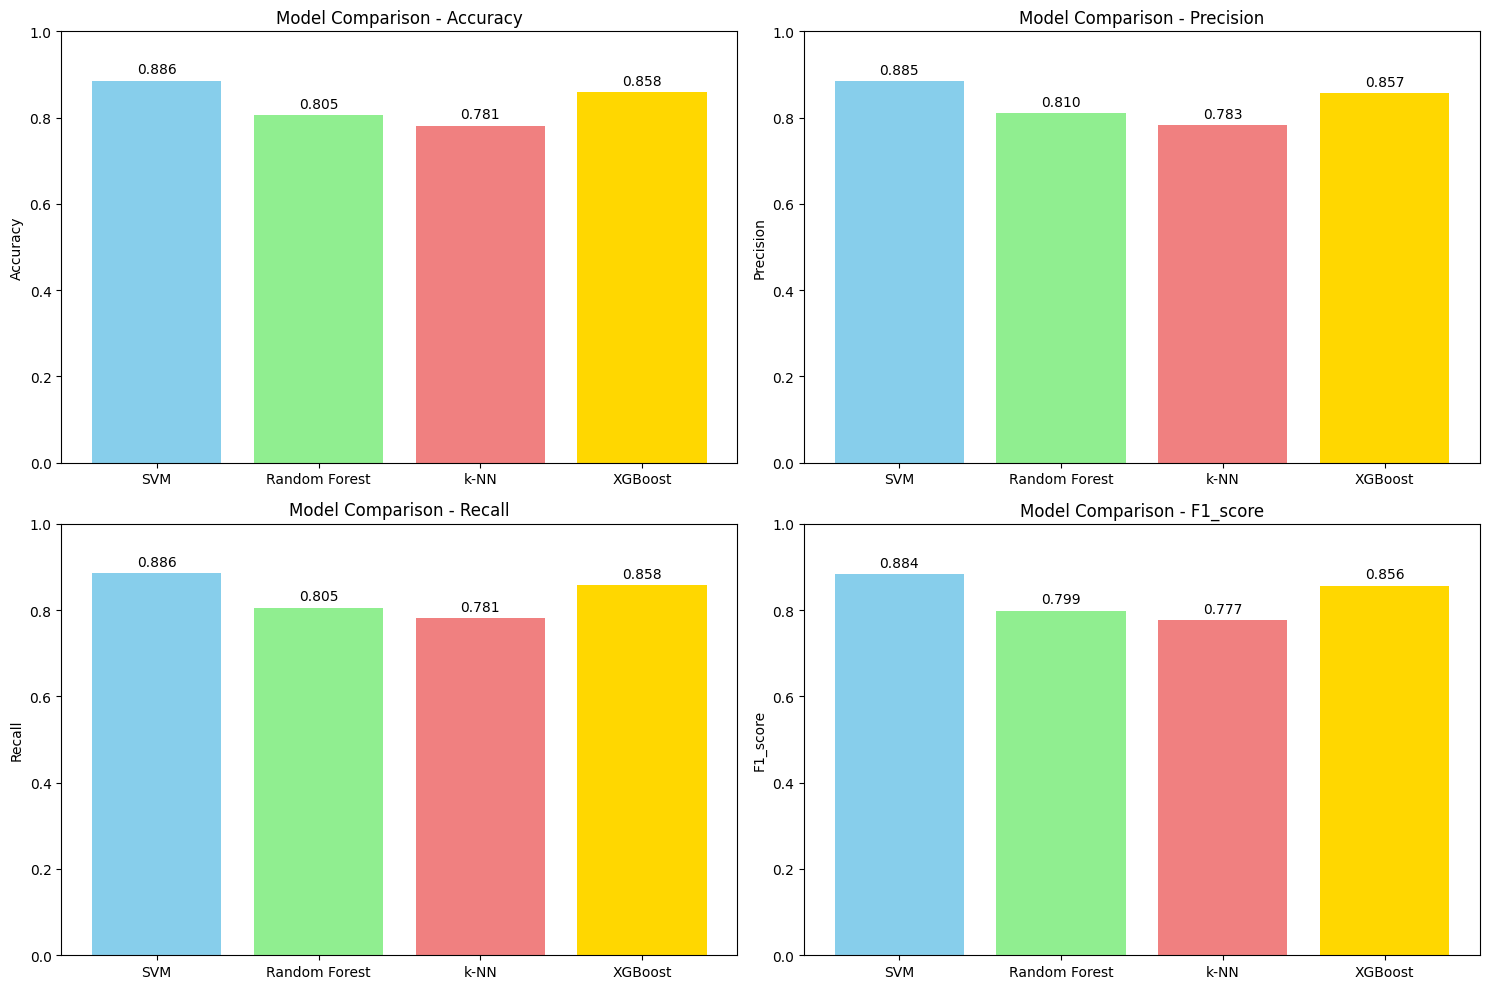

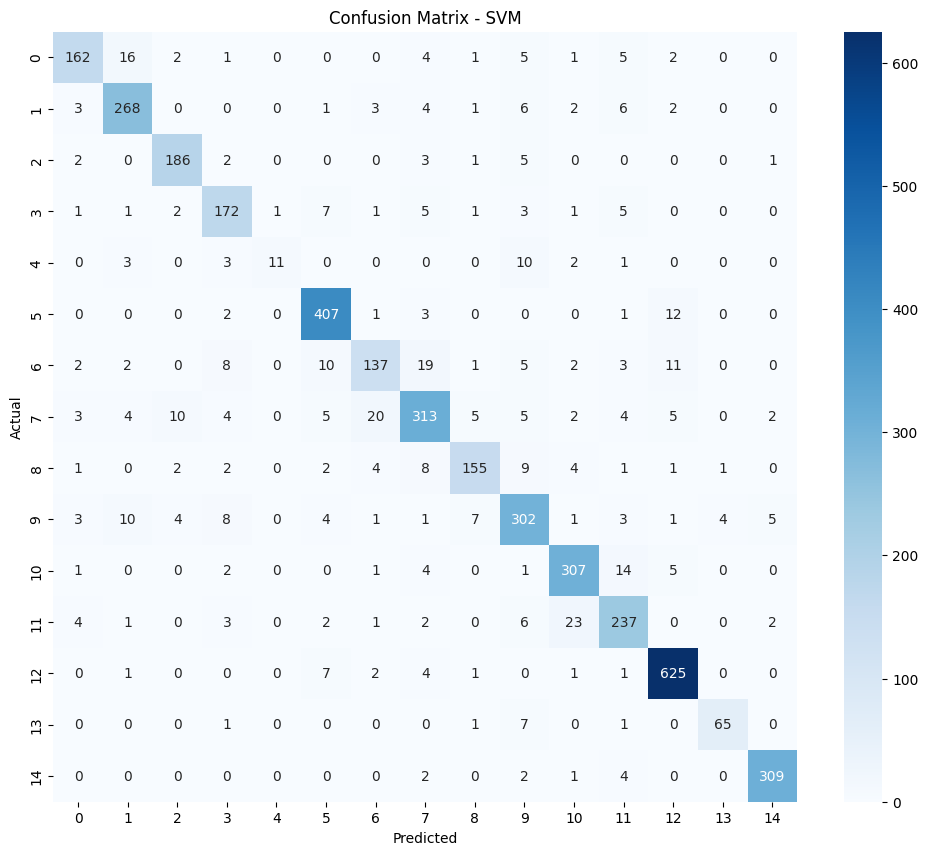


FINAL RESULTS SUMMARY

SVM:
  Test Accuracy: 0.8857
  Precision: 0.8851
  Recall: 0.8857
  F1-Score: 0.8839

Random Forest:
  Test Accuracy: 0.8055
  Precision: 0.8099
  Recall: 0.8055
  F1-Score: 0.7985

k-NN:
  Test Accuracy: 0.7812
  Precision: 0.7826
  Recall: 0.7812
  F1-Score: 0.7768

XGBoost:
  Test Accuracy: 0.8583
  Precision: 0.8570
  Recall: 0.8583
  F1-Score: 0.8564

Best Model: SVM with accuracy 0.8857

Class distribution:
  Pepper__bell___Bacterial_spot: 997 images
  Pepper__bell___healthy: 1478 images
  Potato___Early_blight: 1000 images
  Potato___Late_blight: 1000 images
  Potato___healthy: 152 images
  Tomato_Bacterial_spot: 2127 images
  Tomato_Early_blight: 1000 images
  Tomato_Late_blight: 1909 images
  Tomato_Leaf_Mold: 952 images
  Tomato_Septoria_leaf_spot: 1771 images
  Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
  Tomato__Target_Spot: 1404 images
  Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
  Tomato__Tomato_mosaic_virus: 373 images
  Toma

In [1]:
import os
import numpy as np
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

class PlantDiseaseDetector:
    def __init__(self, data_path, img_size=(128, 128)):
        """
        Initialize the Plant Disease Detector
        
        Args:
            data_path (str): Path to PlantVillage dataset directory
            img_size (tuple): Target image size for resizing
        """
        self.data_path = data_path
        self.img_size = img_size
        self.classes = []
        self.images = []
        self.labels = []
        self.feature_names = []
        self.X_train, self.X_test, self.y_train, self.y_test = None, None, None, None
        self.scaler = StandardScaler()
        self.le = LabelEncoder()
        
        # Define fixed feature dimensions
        self.feature_dimensions = {
            'shape': 11,      # 7 Hu moments + 4 contour features
            'texture': 20,    # 4 GLCM + 16 LBP
            'color': 21,      # 15 RGB + 6 HSV
            'edge': 3         # 3 edge features
        }
        self.total_features = sum(self.feature_dimensions.values())
        
        # Initialize models
        self.models = {
            'SVM': SVC(random_state=42, probability=True),
            'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
            'k-NN': KNeighborsClassifier(n_jobs=-1),
            'XGBoost': XGBClassifier(random_state=42, eval_metric='mlogloss', n_jobs=-1)
        }
        
        self.results = {}
        
    def load_data(self):
        """
        Load ALL images from PlantVillage dataset without any limits
        """
        print("Loading PlantVillage dataset (all images)...")
        
        self.classes = [d for d in os.listdir(self.data_path) 
                       if os.path.isdir(os.path.join(self.data_path, d))]
        
        print(f"Found {len(self.classes)} classes")
        
        total_images = 0
        for class_name in tqdm(self.classes, desc="Loading classes"):
            class_path = os.path.join(self.data_path, class_name)
            image_files = [f for f in os.listdir(class_path) 
                          if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            
            print(f"  {class_name}: {len(image_files)} images")
            
            for img_file in tqdm(image_files, desc=f"Loading {class_name}", leave=False):
                img_path = os.path.join(class_path, img_file)
                try:
                    # Load and preprocess image
                    img = self._load_and_preprocess_image(img_path)
                    if img is not None:
                        self.images.append(img)
                        self.labels.append(class_name)
                        total_images += 1
                except Exception as e:
                    print(f"Error loading {img_path}: {e}")
        
        print(f"Loaded {total_images} images from {len(self.classes)} classes")
        
    def _load_and_preprocess_image(self, img_path):
        """
        Load and preprocess a single image
        """
        # Load image
        img = cv2.imread(img_path)
        if img is None:
            return None
            
        # Resize image
        img = cv2.resize(img, self.img_size)
        
        # Convert BGR to RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        return img
    
    def extract_features(self):
        """
        Extract comprehensive feature set as described in the research paper
        """
        print("Extracting features...")
        
        features_list = []
        
        for img in tqdm(self.images, desc="Extracting features"):
            features = []
            
            # Convert to grayscale for shape and texture features
            gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
            
            # 1. Shape Features (Hu Moments, Contour-based descriptors)
            shape_features = self._extract_shape_features(gray)
            features.extend(shape_features)
            
            # 2. Texture Features (GLCM, LBP)
            texture_features = self._extract_texture_features(gray)
            features.extend(texture_features)
            
            # 3. Color Features (RGB and HSV statistics)
            color_features = self._extract_color_features(img)
            features.extend(color_features)
            
            # 4. Edge/Vein Features (Canny edge detector)
            edge_features = self._extract_edge_features(gray)
            features.extend(edge_features)
            
            # Ensure consistent feature length
            if len(features) != self.total_features:
                # Pad with zeros if needed
                if len(features) < self.total_features:
                    features.extend([0] * (self.total_features - len(features)))
                else:
                    features = features[:self.total_features]
            
            features_list.append(features)
        
        # Create feature matrix
        self.X = np.array(features_list)
        
        # Encode labels
        self.y = self.le.fit_transform(self.labels)
        
        print(f"Feature matrix shape: {self.X.shape}")
        print(f"Number of features: {self.X.shape[1]}")
        
    def _extract_shape_features(self, gray_img):
        """
        Extract shape features including Hu moments and contour descriptors
        Always return exactly 11 features
        """
        features = []
        
        try:
            # Threshold image for contour detection
            _, thresh = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            
            # Find contours
            contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            
            if contours:
                # Get largest contour
                contour = max(contours, key=cv2.contourArea)
                
                # Hu moments (7 features)
                moments = cv2.moments(contour)
                hu_moments = cv2.HuMoments(moments).flatten()
                # Normalize Hu moments to avoid very small values
                hu_moments = -np.sign(hu_moments) * np.log10(np.abs(hu_moments) + 1e-10)
                features.extend(hu_moments.tolist())
                
                # Contour-based descriptors (4 features)
                area = cv2.contourArea(contour)
                perimeter = cv2.arcLength(contour, True)
                
                # Circularity
                circularity = 4 * np.pi * area / (perimeter ** 2) if perimeter > 0 else 0
                features.append(circularity)
                
                # Aspect ratio
                x, y, w, h = cv2.boundingRect(contour)
                aspect_ratio = float(w) / h if h > 0 else 0
                features.append(aspect_ratio)
                
                # Solidity
                hull = cv2.convexHull(contour)
                hull_area = cv2.contourArea(hull)
                solidity = float(area) / hull_area if hull_area > 0 else 0
                features.append(solidity)
                
                # Eccentricity
                eccentricity = 0
                if len(contour) >= 5:
                    try:
                        ellipse = cv2.fitEllipse(contour)
                        major_axis = max(ellipse[1])
                        minor_axis = min(ellipse[1])
                        eccentricity = np.sqrt(1 - (minor_axis ** 2) / (major_axis ** 2)) if major_axis > 0 else 0
                    except:
                        eccentricity = 0
                features.append(eccentricity)
            else:
                # If no contours found, add zeros
                features.extend([0] * 11)
        except:
            # If any error, return zeros
            features.extend([0] * 11)
        
        # Ensure exactly 11 features
        return features[:11] if len(features) >= 11 else features + [0] * (11 - len(features))
    
    def _extract_texture_features(self, gray_img):
        """
        Extract texture features using GLCM and LBP
        Always return exactly 20 features
        """
        features = []
        
        try:
            # GLCM features (4 features)
            glcm_features = self._calculate_glcm_features(gray_img)
            features.extend(glcm_features)
            
            # LBP features (16 features)
            lbp_features = self._calculate_lbp_features(gray_img)
            features.extend(lbp_features)
        except:
            # If any error, return zeros
            features.extend([0] * 20)
        
        # Ensure exactly 20 features
        return features[:20] if len(features) >= 20 else features + [0] * (20 - len(features))
    
    def _calculate_glcm_features(self, gray_img):
        """
        Calculate GLCM texture features - always return 4 features
        """
        try:
            # Calculate gradients (approximation of texture)
            sobelx = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0, ksize=3)
            sobely = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1, ksize=3)
            
            gradient_magnitude = np.sqrt(sobelx**2 + sobely**2)
            gradient_direction = np.arctan2(sobely, sobelx)
            
            # Statistical features from gradients
            features = [
                np.mean(gradient_magnitude),
                np.std(gradient_magnitude),
                np.mean(gradient_direction),
                np.std(gradient_direction)
            ]
        except:
            features = [0, 0, 0, 0]
        
        return features[:4] if len(features) >= 4 else features + [0] * (4 - len(features))
    
    def _calculate_lbp_features(self, gray_img):
        """
        Calculate simplified LBP features - always return 16 features
        """
        try:
            # Simplified LBP implementation
            height, width = gray_img.shape
            lbp_image = np.zeros_like(gray_img, dtype=np.uint8)
            
            for i in range(1, height-1):
                for j in range(1, width-1):
                    center = gray_img[i, j]
                    binary_pattern = 0
                    # 8 neighbors (simplified)
                    neighbors = [
                        gray_img[i-1, j-1], gray_img[i-1, j], gray_img[i-1, j+1],
                        gray_img[i, j-1], gray_img[i, j+1],
                        gray_img[i+1, j-1], gray_img[i+1, j], gray_img[i+1, j+1]
                    ]
                    
                    for k, neighbor in enumerate(neighbors):
                        if neighbor >= center:
                            binary_pattern |= (1 << k)
                    
                    lbp_image[i, j] = binary_pattern
            
            # Histogram of LBP patterns
            hist, _ = np.histogram(lbp_image.ravel(), bins=256, range=[0, 256])
            hist = hist / (hist.sum() + 1e-10)  # Normalize
            
            # Return first 16 bins as features
            features = hist[:16].tolist()
        except:
            features = [0] * 16
        
        return features[:16] if len(features) >= 16 else features + [0] * (16 - len(features))
    
    def _extract_color_features(self, rgb_img):
        """
        Extract color features from RGB and HSV color spaces
        Always return exactly 21 features
        """
        features = []
        
        try:
            # RGB color statistics (15 features: 5 stats × 3 channels)
            for channel in range(3):
                channel_data = rgb_img[:, :, channel].ravel()
                channel_features = [
                    np.mean(channel_data),
                    np.std(channel_data),
                    np.median(channel_data),
                    np.min(channel_data),
                    np.max(channel_data)
                ]
                features.extend(channel_features)
            
            # Convert to HSV
            hsv_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2HSV)
            
            # HSV color statistics (6 features: 2 stats × 3 channels)
            for channel in range(3):
                channel_data = hsv_img[:, :, channel].ravel()
                channel_features = [
                    np.mean(channel_data),
                    np.std(channel_data)
                ]
                features.extend(channel_features)
        except:
            features = [0] * 21
        
        # Ensure exactly 21 features
        return features[:21] if len(features) >= 21 else features + [0] * (21 - len(features))
    
    def _extract_edge_features(self, gray_img):
        """
        Extract edge features using Canny edge detector
        Always return exactly 3 features
        """
        try:
            # Apply Canny edge detection
            edges = cv2.Canny(gray_img, 50, 150)
            
            # Edge statistics
            edge_density = np.sum(edges > 0) / (gray_img.shape[0] * gray_img.shape[1])
            
            # Find contours in edges
            contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            
            if contours:
                total_edge_length = sum(cv2.arcLength(cnt, True) for cnt in contours)
                avg_edge_length = total_edge_length / len(contours) if len(contours) > 0 else 0
            else:
                total_edge_length = 0
                avg_edge_length = 0
            
            features = [edge_density, total_edge_length, avg_edge_length]
        except:
            features = [0, 0, 0]
        
        return features[:3] if len(features) >= 3 else features + [0] * (3 - len(features))
    
    def prepare_data(self, test_size=0.2, apply_pca=False, n_components=50):
        """
        Prepare data for training with optional PCA
        """
        print("Preparing data for training...")
        
        # Split data
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            self.X, self.y, test_size=test_size, random_state=42, stratify=self.y
        )
        
        # Standardize features
        self.X_train_scaled = self.scaler.fit_transform(self.X_train)
        self.X_test_scaled = self.scaler.transform(self.X_test)
        
        # Apply PCA if requested
        if apply_pca:
            n_components = min(n_components, self.X_train_scaled.shape[1])
            print(f"Applying PCA with {n_components} components...")
            pca = PCA(n_components=n_components, random_state=42)
            self.X_train_scaled = pca.fit_transform(self.X_train_scaled)
            self.X_test_scaled = pca.transform(self.X_test_scaled)
            print(f"Explained variance ratio: {np.sum(pca.explained_variance_ratio_):.4f}")
        
        print(f"Training set: {self.X_train_scaled.shape}")
        print(f"Test set: {self.X_test_scaled.shape}")
    
    def train_models(self):
        """
        Train all models
        """
        print("Training models...")
        
        for name, model in self.models.items():
            print(f"Training {name}...")
            model.fit(self.X_train_scaled, self.y_train)
            print(f"  {name} training completed")
    
    def evaluate_models(self):
        """
        Evaluate all models and store results
        """
        print("Evaluating models...")
        
        for name, model in self.models.items():
            try:
                # Predictions
                y_pred = model.predict(self.X_test_scaled)
                
                # Calculate metrics
                accuracy = accuracy_score(self.y_test, y_pred)
                precision = precision_score(self.y_test, y_pred, average='weighted', zero_division=0)
                recall = recall_score(self.y_test, y_pred, average='weighted', zero_division=0)
                f1 = f1_score(self.y_test, y_pred, average='weighted', zero_division=0)
                
                # Store results
                self.results[name] = {
                    'model': model,
                    'accuracy': accuracy,
                    'precision': precision,
                    'recall': recall,
                    'f1_score': f1,
                    'predictions': y_pred
                }
                
                print(f"{name} Results:")
                print(f"  Accuracy: {accuracy:.4f}")
                print(f"  Precision: {precision:.4f}")
                print(f"  Recall: {recall:.4f}")
                print(f"  F1-Score: {f1:.4f}")
                print()
            except Exception as e:
                print(f"Error evaluating {name}: {e}")
                self.results[name] = {
                    'model': model,
                    'accuracy': 0,
                    'precision': 0,
                    'recall': 0,
                    'f1_score': 0,
                    'predictions': None
                }
    
    def cross_validate(self, cv_folds=3):  # Reduced from 5 to 3 for faster execution with large dataset
        """
        Perform cross-validation for all models
        """
        print(f"Performing {cv_folds}-fold cross-validation...")
        
        cv_results = {}
        for name, model in self.models.items():
            try:
                cv_scores = cross_val_score(model, self.X_train_scaled, self.y_train, 
                                          cv=cv_folds, scoring='accuracy', n_jobs=-1)
                cv_results[name] = {
                    'mean_score': np.mean(cv_scores),
                    'std_score': np.std(cv_scores),
                    'scores': cv_scores
                }
                print(f"{name} CV Accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")
            except Exception as e:
                print(f"Error in CV for {name}: {e}")
                cv_results[name] = {
                    'mean_score': 0,
                    'std_score': 0,
                    'scores': [0] * cv_folds
                }
        
        return cv_results
    
    def plot_results(self):
        """
        Plot comparison of model performances
        """
        if not self.results:
            print("No results to plot")
            return
            
        # Model comparison bar plot
        metrics = ['accuracy', 'precision', 'recall', 'f1_score']
        model_names = list(self.results.keys())
        
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        axes = axes.ravel()
        
        for i, metric in enumerate(metrics):
            scores = [self.results[name][metric] for name in model_names]
            colors = ['skyblue', 'lightgreen', 'lightcoral', 'gold']
            bars = axes[i].bar(model_names, scores, color=colors)
            axes[i].set_title(f'Model Comparison - {metric.capitalize()}')
            axes[i].set_ylabel(metric.capitalize())
            axes[i].set_ylim(0, 1)
            
            # Add value labels on bars
            for j, v in enumerate(scores):
                axes[i].text(j, v + 0.01, f'{v:.3f}', ha='center', va='bottom')
        
        plt.tight_layout()
        plt.show()
        
        # Confusion matrix for best model
        best_model_name = max(self.results.keys(), 
                            key=lambda x: self.results[x]['accuracy'])
        best_model_results = self.results[best_model_name]
        
        if best_model_results['predictions'] is not None:
            cm = confusion_matrix(self.y_test, best_model_results['predictions'])
            
            plt.figure(figsize=(12, 10))
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
            plt.title(f'Confusion Matrix - {best_model_name}')
            plt.xlabel('Predicted')
            plt.ylabel('Actual')
            plt.show()
    
    def run_complete_pipeline(self, test_size=0.2, apply_pca=True):
        """
        Run the complete pipeline from data loading to evaluation
        """
        try:
            # Step 1: Load data (ALL images, no limits)
            self.load_data()
            
            # Step 2: Extract features
            self.extract_features()
            
            # Step 3: Prepare data
            self.prepare_data(test_size=test_size, apply_pca=apply_pca)
            
            # Step 4: Train models
            self.train_models()
            
            # Step 5: Cross-validation
            cv_results = self.cross_validate()
            
            # Step 6: Evaluate on test set
            self.evaluate_models()
            
            # Step 7: Plot results
            self.plot_results()
            
            return self.results, cv_results
            
        except Exception as e:
            print(f"Error in pipeline: {e}")
            import traceback
            traceback.print_exc()
            return {}, {}

# Example usage
if __name__ == "__main__":
    # Initialize the detector
    detector = PlantDiseaseDetector(data_path="/kaggle/input/plantdisease/PlantVillage")
    
    # Run complete pipeline with ALL images
    print("Starting complete pipeline with ALL images from PlantVillage dataset...")
    results, cv_results = detector.run_complete_pipeline(
        test_size=0.2,
        apply_pca=True  # Recommended for large datasets
    )
    
    # Print final results
    print("\n" + "="*50)
    print("FINAL RESULTS SUMMARY")
    print("="*50)
    
    for model_name, result in results.items():
        print(f"\n{model_name}:")
        print(f"  Test Accuracy: {result['accuracy']:.4f}")
        print(f"  Precision: {result['precision']:.4f}")
        print(f"  Recall: {result['recall']:.4f}")
        print(f"  F1-Score: {result['f1_score']:.4f}")
    
    if results:
        # Find best model
        best_model = max(results.items(), key=lambda x: x[1]['accuracy'])
        print(f"\nBest Model: {best_model[0]} with accuracy {best_model[1]['accuracy']:.4f}")
        
        # Print class distribution
        print(f"\nClass distribution:")
        unique, counts = np.unique(detector.labels, return_counts=True)
        for class_name, count in zip(unique, counts):
            print(f"  {class_name}: {count} images")